# BANKHEAD NATIONAL FOREST (BNF) ARM DATA DISCOVERY
This notebook examines 

In [6]:
# Imports
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as colors

import getpass
import act

## Establish Notebook Parameters

### Relevant dates 
    We are focused on the TBS datastreams and dates.  
    March 21 thru April 5, 2026 (2026-03-21 --> 2026-04-05)  
     
### Recommended Aerosol Datastreams

| Facility | Datastream | Description |
| --- | --- | --- |
| bnf.M1 | [bnftbspopsM1.b1](https://adc.arm.gov/discovery/results/id::bnftbspopsM1.b1_dn_705_1380_particul_tbspops_aerosol?dataLevel=b1&showDetails=true) | Aerosol concentration and particle size distribution |
| bnf.S1 | [bnftbspopsS1.b1](https://adc.arm.gov/discovery/results/id::bnftbspopsS1.b1_dn_135_150_particul_tbspops_aerosol?dataLevel=b1&showDetails=true) | Aerosol concentration and particle size distribution |

### Meteorological and Profile Datastreams
| Facility | Datastream | Description |
| --- | --- | --- |
| bnf.M1 | [bnftbsmergedM1.c1](https://adc.arm.gov/discovery/results/id::bnftbsmergedM1.c1_tbsimet_air_temperature_micro_tbsmerged_airborne?dataLevel=c1&showDetails=true) | Corrected air temperature (Merged) |
| bnf.S1 | [bnftbsimetxq2S1.b1](https://adc.arm.gov/discovery/results/id::bnftbsimetxq2S1.b1_rh_macro_tbsmet_airborne?dataLevel=b1&showDetails=true) | Relative humidity (iMet-XQ2) |
| bnf.S1 | [bnftbsimetS1.b1](https://adc.arm.gov/discovery/results/id::bnftbsimetS1.b1_air_temperature_lwnarrow_tbsmet_atmprof?dataLevel=b1&showDetails=true) | Air temperature (iMet) |
| bnf.S1 | [bnftbswindS1.b1](https://adc.arm.gov/discovery/results/id::bnftbswindS1.b1_vertical_wind_sfcflux_tbswind_airborne?dataLevel=b1&showDetails=true) | Vertical wind component |
| bnf.M1 | [bnftbsdtsch1M1.b1](https://adc.arm.gov/discovery/results/id::bnftbsdtsch1M1.b1_temperature_lwbroad_tbsdts_airborne?dataLevel=b1&showDetails=true) | Temperature profiles (DTS Channel 1) |
 
### Specialized and Ground Datastreams
| Facility | Datastream | Description |
| --- | --- | --- |
| bnf.M1 | [bnftbscpcM1.b1](https://adc.arm.gov/discovery/results/id::bnftbscpcM1.b1_total_concentration_microchem_tbscpc_airborne?dataLevel=b1&showDetails=true) | Total aerosol number concentration > 10 nm |
| bnf.M1 | [bnftbsinpM1.a1](https://adc.arm.gov/discovery/results/id::bnftbsinpM1.a1_n_inp_stp_micro_tbsins_airborne?dataLevel=a1&showDetails=true) | Ice nucleating particles |
| bnf.M1 | [bnftbsgroundM1.b1](https://adc.arm.gov/discovery/results/id::bnftbsgroundM1.b1_pressure_sfcmet_tbsground_sfcmet?dataLevel=b1&showDetails=true) | Ground air pressure |
| bnf.M1 | [bnfarmtrajtbsM1.c1](https://adc.arm.gov/discovery/results/id::bnfarmtrajtbsM1.c1_altitude_diagnostic_armtraj-air_atmprof?dataLevel=c1&showDetails=true) | Airmass altitude trajectories |
 
## Sources:  [ARM Data Discovery](https://adc.arm.gov/discovery/)

Meteorological data from flux tower at S10:
Based on the available metadata for the Bankhead National Forest (BNF) site, the meteorological tower (Facility S10) captured several high-frequency datastreams during the period of March 21 to April 5, 2026. These datastreams provide 1-second measurements of 3D winds, temperature, humidity, and vapor pressure at various heights. The following datastreams were active during the specified timeframe:

| Datastream | Height | Description | Link |
| :--- | :--- | :--- | :--- |

| `bnftowermet43mS10.a1` | 43m | 1-second temperature, humidity, vapor pressure, and 3D winds | [DOI: 10.5439/2570718](https://doi.org/10.5439/2570718) |

| `bnftowermet38mS10.a1` | 38m | 1-second temperature, humidity, vapor pressure, and 3D winds | [DOI: 10.5439/3006093](https://doi.org/10.5439/3006093) |

| `bnftowermet20mS10.a1` | 20m | 1-second temperature, humidity, vapor pressure, and 3D winds | [DOI: 10.5439/3006092](https://doi.org/10.5439/3006092) |

| `bnftowermetS10.b1` | Various | Processed meteorological data (including 43m averages) | [DOI: 10.5439/1501941](https://doi.org/10.5439/1501941) |

## Sources
1. [ARM Data Discovery](https://adc.arm.gov/discovery/results/site_code::bnf/instrument_code::twr)
2. [Tower Instrument Info](https://www.arm.gov/capabilities/instruments/twr)
3. [Tower Instrument Handbook](http://www.arm.gov/publications/tech_reports/handbooks/twr_handbook.pdf)


    

### ARM Live Token
---
You will also need an account and token to download data using the ARM Live webservice. Navigate to the [webservice information page](https://adc.arm.gov/armlive/) and log in to get your token. Your account username will be your ARM username.

We will use the [Atmospheric Community Toolkit (ACT)](https://arm-doe.github.io/ACT/) Discovery tool to download and look at ARM Data. 

We need to identify the relevant datastreams. 

Code will look like 
```python
act.discovery.download_arm_data(arm_username, arm_token, [DATASTREAM], [START_DATE], END_DATE)
```


In [4]:
# Note - recommended ARM Live token to be set as an environmental variable
# Check for env variables, otherwise set your username and token here!
if "ARM_USERNAME" in os.environ:
    arm_username = os.getenv("ARM_USERNAME")
else:
    arm_username = input("Enter ARM username: ").strip()
if "ARM_TOKEN" in os.environ:
    arm_token = os.getenv("ARM_TOKEN")
else:
    arm_token = getpass.getpass("Enter ARM token (hidden): ").strip()

Enter ARM username:  marosites
Enter ARM token (hidden):  ········


In [38]:
# Set the datastream and start/enddates (2026-03-21 --> 2026-04-05)
tbs_pops_datastream = "bnftbspopsS1.b1"

startdate = '2026-03-21'
enddate = '2026-04-05'

# Use ACT to easily download the data.  Watch for the data citation!  Show some support
# for ARM's instrument experts and cite their data if you use it in a publication
result_tbs_pops = act.discovery.download_arm_data(arm_username, arm_token, tbs_pops_datastream, startdate, enddate)

[DOWNLOADING] bnftbspopsS1.b1.20260329.012300.nc

If you use these data to prepare a publication, please cite:

Mei, F., Stephenson, J., & Pekour, M. Portable Optical Particle Spectrometer
aboard Tethered Balloon System (TBSPOPS), 2026-03-21 to 2026-04-05, Bankhead
National Forest, AL, USA; Long-term Mobile Facility (BNF), Bankhead National
Forest, AL, AMF3 (Collocated Main Site)  (S1). Atmospheric Radiation Measurement
(ARM) User Facility. https://doi.org/10.5439/1827703



In [39]:
ds_tbs_pops = act.io.read_arm_netcdf(result_tbs_pops)
ds_tbs_pops

<xarray.Dataset> Size: 2MB
Dimensions:                 (time: 12121, num_pops: 1)
Coordinates:
  * time                    (time) datetime64[ns] 97kB 2026-03-29T01:23:00 .....
Dimensions without coordinates: num_pops
Data variables: (12/29)
    base_time               datetime64[ns] 8B 2026-03-29
    time_offset             (time) datetime64[ns] 97kB 2026-03-29T01:23:00 .....
    imet_temperature        (time, num_pops) float32 48kB dask.array<chunksize=(12121, 1), meta=np.ndarray>
    qc_imet_temperature     (time, num_pops) int32 48kB dask.array<chunksize=(12121, 1), meta=np.ndarray>
    imet_pressure           (time, num_pops) float32 48kB dask.array<chunksize=(12121, 1), meta=np.ndarray>
    qc_imet_pressure        (time, num_pops) int32 48kB dask.array<chunksize=(12121, 1), meta=np.ndarray>
    ...                      ...
    dn_1380_1760            (time, num_pops) float32 48kB dask.array<chunksize=(12121, 1), meta=np.ndarray>
    dn_1760_2550            (time, num_pops) float32 48kB dask.array<chunksize=(12121, 1), meta=np.ndarray>
    dn_2550_3615            (time, num_pops) float32 48kB dask.array<chunksize=(12121, 1), meta=np.ndarray>
    lat                     (time, num_pops) float32 48kB dask.array<chunksize=(12121, 1), meta=np.ndarray>
    lon                     (time, num_pops) float32 48kB dask.array<chunksize=(12121, 1), meta=np.ndarray>
    alt                     (time, num_pops) float32 48kB dask.array<chunksize=(12121, 1), meta=np.ndarray>
Attributes: (12/17)
    command_line:          tbspopsme_ingest -s bnf -f S1 --max-runtime 86400
    Conventions:           ARM-1.3
    process_version:       ingest-tbspopsme-1.3-0.el9
    dod_version:           tbspops-b1-2.0
    input_source:          /data/collection/bnf/bnftbspopsS1.01/bnf.S1.tbs.po...
    site_id:               bnf
    ...                    ...
    doi:                   10.5439/1504073
    history:               created by user armflowprod on machine prod-slurmn...
    _file_dates:           ['20260329']
    _file_times:           ['012300']
    _datastream:           bnftbspopsS1.b1
    _arm_standards_flag:   1

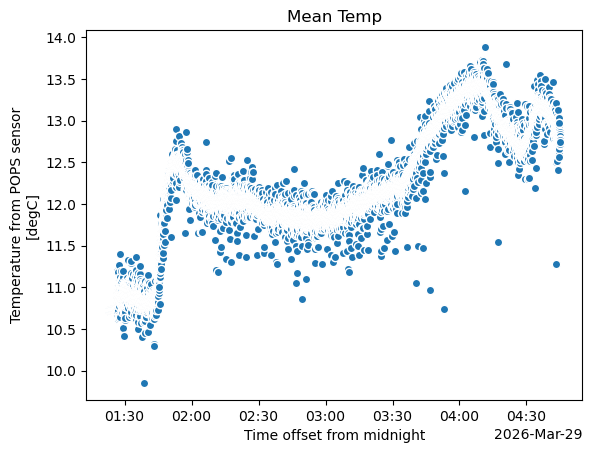

In [40]:
ds_tbs_pops['temperature'].plot.scatter()
plt.title('Mean Temp')
plt.show()


In [41]:
# ACT QC
ds_tbs_pops.clean.cleanup()

variable = 'temperature'
ds_tbs_pops = act.qc.add_dqr_to_qc(ds_tbs_pops, variable=variable)

ConnectTimeout: HTTPSConnectionPool(host='dqr-web-service.svcs.arm.gov', port=443): Max retries exceeded with url: /dqr_full/bnftbspopsS1.b1/20260329/20260329/incorrect,suspect (Caused by ConnectTimeoutError(<urllib3.connection.HTTPSConnection object at 0x7fada2cd1390>, 'Connection to dqr-web-service.svcs.arm.gov timed out. (connect timeout=None)'))

In [ ]:
ds_tbs_pop

In [ ]:
# Next, let's take a look at visualizing the quality control information
# Create a plotting display object with 2 plots
display = act.plotting.TimeSeriesDisplay(ds_tbs_pops, figsize=(15, 10), subplot_shape=(2,))

# Plot up the variable in the first plot
display.plot(variable, subplot_index=(0,))

# Plot up a day/night background
display.day_night_background(subplot_index=(0,))

# Plot up the QC variable in the second plot
display.qc_flag_block_plot(variable, subplot_index=(1,))
plt.show()